<a href="https://colab.research.google.com/github/soumyakumbar06/Machine-Learning-Lab-Exp/blob/main/Lab_2(ML).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report

df = pd.read_csv('/content/datapy.csv', on_bad_lines='skip')
df.columns = df.columns.str.strip()

# Updated to match the columns actually present in datapy.csv
numeric_cols = ['age', 'studyhours', 'Attendence', 'PreviousMarks']
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print("DataFrame head after reading and initial type conversion:")
print(df.head())
print("\nDataFrame info after reading and initial type conversion:")
df.info()

DataFrame head after reading and initial type conversion:
   age  gender  studyhours  Attendence  PreviousMarks AssignmentScore
0   18  female          25        75.0             55            pass
1   19    male          45        68.0             61            fail
2   20    male          35        23.0             21            fail
3    1  female          39         NaN             45            pass
4   19  female           4        11.0             99            pass

DataFrame info after reading and initial type conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              11 non-null     int64  
 1   gender           11 non-null     object 
 2   studyhours       11 non-null     int64  
 3   Attendence       9 non-null      float64
 4   PreviousMarks    11 non-null     int64  
 5   AssignmentScore  11 non-null     o

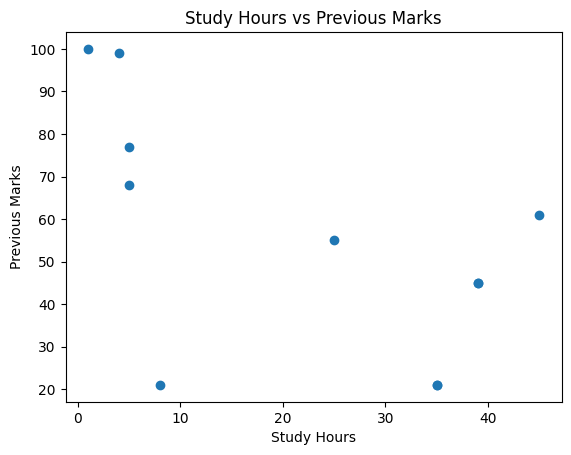

In [33]:
plt.scatter(df["studyhours"], df["PreviousMarks"])
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.title("Study Hours vs Previous Marks")
plt.show()

In [34]:
df["PerformanceScore"] = (0.4 * df["PreviousMarks"] + 0.3 * df["Attendence"])

In [35]:
df

,age,gender,studyhours,Attendence,PreviousMarks,AssignmentScore,PerformanceScore
0,18,female,25,75.0,55,pass,44.5
1,19,male,45,68.0,61,fail,44.8
2,20,male,35,23.0,21,fail,15.3
3,1,female,39,NaN,45,pass,NaN
4,19,female,4,11.0,99,pass,42.9
5,21,female,8,56.0,21,fail,25.2
6,21,male,5,NaN,77,fail,NaN
7,23,female,1,8.0,100,pass,42.4
8,20,female,5,45.0,68,pass,40.7
9,20,male,35,23.0,21,fail,15.3


In [36]:
x = df[["studyhours", "Attendence", "PreviousMarks", "PerformanceScore"]]
y = df["AssignmentScore"]

In [37]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [38]:
model=DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Handle missing values in X_train by filling with column means
X_train_imputed = X_train.fillna(X_train.mean())

# Identify rows in y_train that are NaN
nan_in_y_train_idx = y_train.isna()

# Remove rows with NaN target values from both X_train_imputed and y_train
X_train_final = X_train_imputed[~nan_in_y_train_idx]
y_train_final = y_train[~nan_in_y_train_idx]

# Fit the model with the cleaned data
model.fit(X_train_final, y_train_final)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [39]:
model.fit(X_train_final, y_train_final)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [40]:
y_pred=model.predict(X_test)
print(y_pred)
result=pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(result)

['pass' 'pass' 'fail']
  Actual Predicted
5   fail      pass
0   pass      pass
9   fail      fail


In [41]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)


Accuracy: 0.6666666666666666


In [42]:
precision=precision_score(y_test,y_pred, pos_label='pass')
print("Precision:",precision)

Precision: 0.5
